In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\DELL\Documents\Veda_Task31
['.ipynb_checkpoints', 'Veda_Task31_OTT_Content_Trend_Analysis.ipynb']


In [4]:
import os
print(os.listdir())

['.ipynb_checkpoints', 'amazon_prime_titles.csv', 'disney_plus_titles.csv', 'netflix_titles.csv', 'Veda_Task31_OTT_Content_Trend_Analysis.ipynb']


In [5]:
netflix = pd.read_csv("netflix_titles.csv")
amazon = pd.read_csv("amazon_prime_titles.csv")
hotstar = pd.read_csv("disney_plus_titles.csv")

print("Netflix shape:", netflix.shape)
print("Amazon Prime shape:", amazon.shape)
print("Disney+ Hotstar shape:", hotstar.shape)

Netflix shape: (8807, 12)
Amazon Prime shape: (9668, 12)
Disney+ Hotstar shape: (1450, 12)


In [6]:
print("Netflix columns:")
print(netflix.columns.tolist())

print("\nAmazon Prime columns:")
print(amazon.columns.tolist())

print("\nDisney+ Hotstar columns:")
print(hotstar.columns.tolist())

Netflix columns:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Amazon Prime columns:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Disney+ Hotstar columns:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


In [7]:
netflix["platform"] = "Netflix"
amazon["platform"] = "Amazon Prime"
hotstar["platform"] = "Disney+ Hotstar"

print("Platform columns added successfully.")
print(netflix["platform"].unique())
print(amazon["platform"].unique())
print(hotstar["platform"].unique())

Platform columns added successfully.
['Netflix']
['Amazon Prime']
['Disney+ Hotstar']


In [8]:
# Combine all OTT platform datasets

ott = pd.concat(
    [netflix, amazon, hotstar],
    ignore_index=True
)

print("Combined Dataset Shape:", ott.shape)

print("\nPlatform Counts:")
print(ott["platform"].value_counts())


Combined Dataset Shape: (19925, 13)

Platform Counts:
platform
Amazon Prime       9668
Netflix            8807
Disney+ Hotstar    1450
Name: count, dtype: int64


In [9]:
# Check missing values in the combined dataset

missing_values = ott.isnull().sum()

print("Missing Values by Column:")
print(missing_values[missing_values > 0])

Missing Values by Column:
director       5190
cast           2248
country       10046
date_added     9526
rating          344
duration          3
dtype: int64


In [10]:
# Check duplicate records

print("Total duplicate rows:", ott.duplicated().sum())

print("\nDuplicate titles:")
print(ott.duplicated(subset=["platform", "title"]).sum())

Total duplicate rows: 0

Duplicate titles:
0


In [11]:
# Movie vs TV Show distribution by platform

type_distribution = pd.crosstab(
    ott["platform"],
    ott["type"]
)

print(type_distribution)

type             Movie  TV Show
platform                       
Amazon Prime      7814     1854
Disney+ Hotstar   1052      398
Netflix           6131     2676


In [12]:
# Calculate Movie vs TV Show percentage by platform

type_percentage = pd.crosstab(
    ott["platform"],
    ott["type"],
    normalize="index"
) * 100

type_percentage = type_percentage.round(2)

print("Movie vs TV Show Percentage by Platform:")
print(type_percentage)

Movie vs TV Show Percentage by Platform:
type             Movie  TV Show
platform                       
Amazon Prime     80.82    19.18
Disney+ Hotstar  72.55    27.45
Netflix          69.62    30.38


In [13]:
# Content count by release year and platform

release_year_platform = (
    ott.groupby(["release_year", "platform"])
       .size()
       .reset_index(name="title_count")
)

print(release_year_platform.head(20))

    release_year         platform  title_count
0           1920     Amazon Prime            3
1           1922     Amazon Prime            2
2           1923     Amazon Prime            1
3           1924     Amazon Prime            1
4           1925     Amazon Prime            8
5           1925          Netflix            1
6           1926     Amazon Prime            2
7           1927     Amazon Prime            1
8           1928  Disney+ Hotstar            1
9           1929     Amazon Prime            4
10          1930     Amazon Prime            5
11          1931     Amazon Prime            3
12          1932     Amazon Prime            8
13          1932  Disney+ Hotstar            3
14          1933     Amazon Prime            5
15          1933  Disney+ Hotstar            3
16          1934     Amazon Prime           12
17          1934  Disney+ Hotstar            4
18          1935     Amazon Prime           15
19          1935  Disney+ Hotstar            4


In [14]:
# Find the latest release year available for each platform

latest_year = ott.groupby("platform")["release_year"].max()

print("Latest Release Year by Platform:")
print(latest_year)

Latest Release Year by Platform:
platform
Amazon Prime       2021
Disney+ Hotstar    2021
Netflix            2021
Name: release_year, dtype: int64


In [15]:
# Top 10 release years by number of titles

top_release_years = (
    ott["release_year"]
    .value_counts()
    .sort_index()
)

print("Release Year Counts:")
print(top_release_years.tail(10))

Release Year Counts:
release_year
2012     530
2013     609
2014     793
2015     984
2016    1484
2017    1663
2018    1835
2019    2058
2020    2029
2021    2159
Name: count, dtype: int64


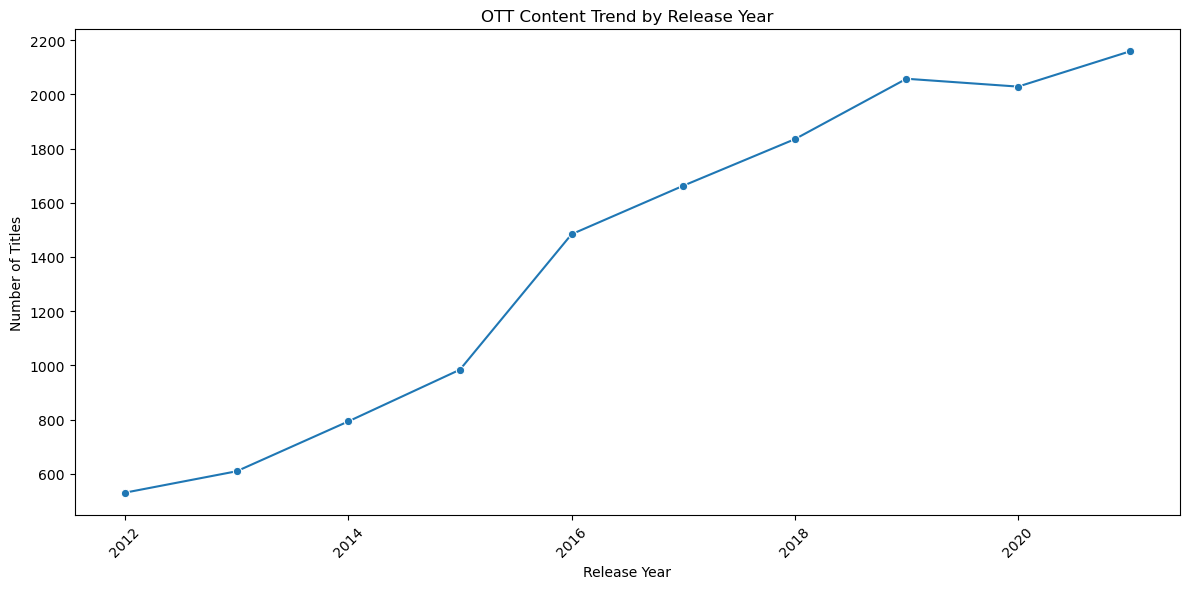

In [16]:
# Visualization 1: OTT Content Trend by Release Year

yearly_content = (
    ott[ott["release_year"] >= 2012]
    .groupby("release_year")
    .size()
    .reset_index(name="title_count")
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=yearly_content,
    x="release_year",
    y="title_count",
    marker="o"
)

plt.title("OTT Content Trend by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

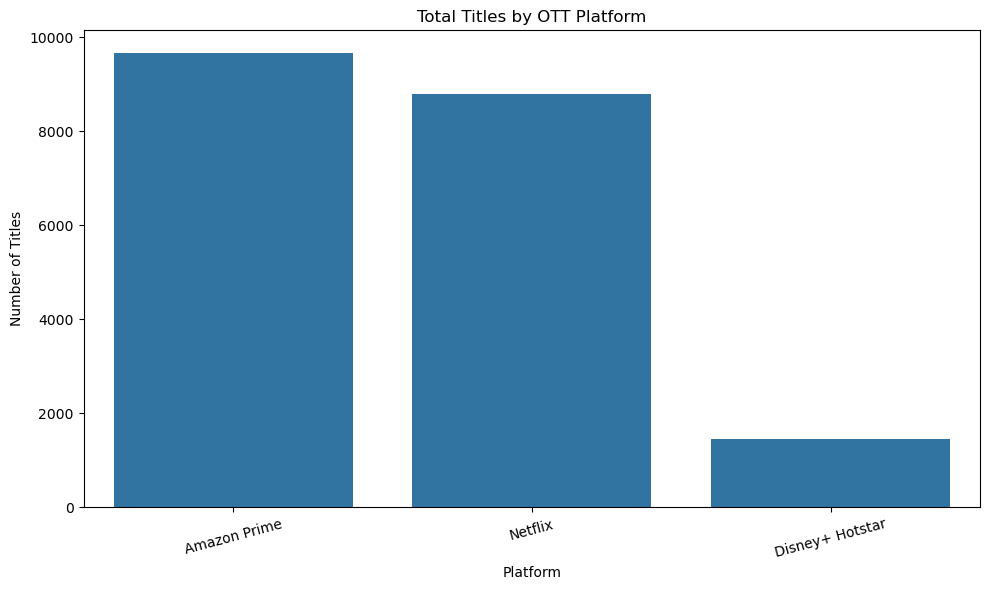

In [17]:
# Visualization 2: Total Titles by Platform

platform_counts = ott["platform"].value_counts().reset_index()
platform_counts.columns = ["platform", "title_count"]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=platform_counts,
    x="platform",
    y="title_count"
)

plt.title("Total Titles by OTT Platform")
plt.xlabel("Platform")
plt.ylabel("Number of Titles")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

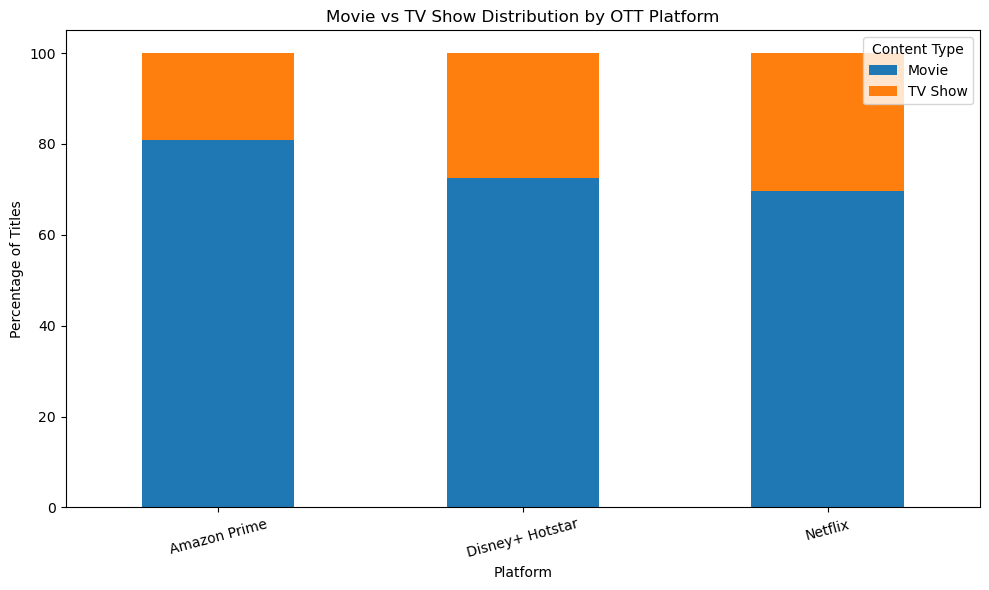

In [18]:
# Visualization 3: Movie vs TV Show Distribution by Platform

type_percentage_plot = type_percentage.reset_index()

type_percentage_plot.plot(
    x="platform",
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Movie vs TV Show Distribution by OTT Platform")
plt.xlabel("Platform")
plt.ylabel("Percentage of Titles")
plt.xticks(rotation=15)
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()

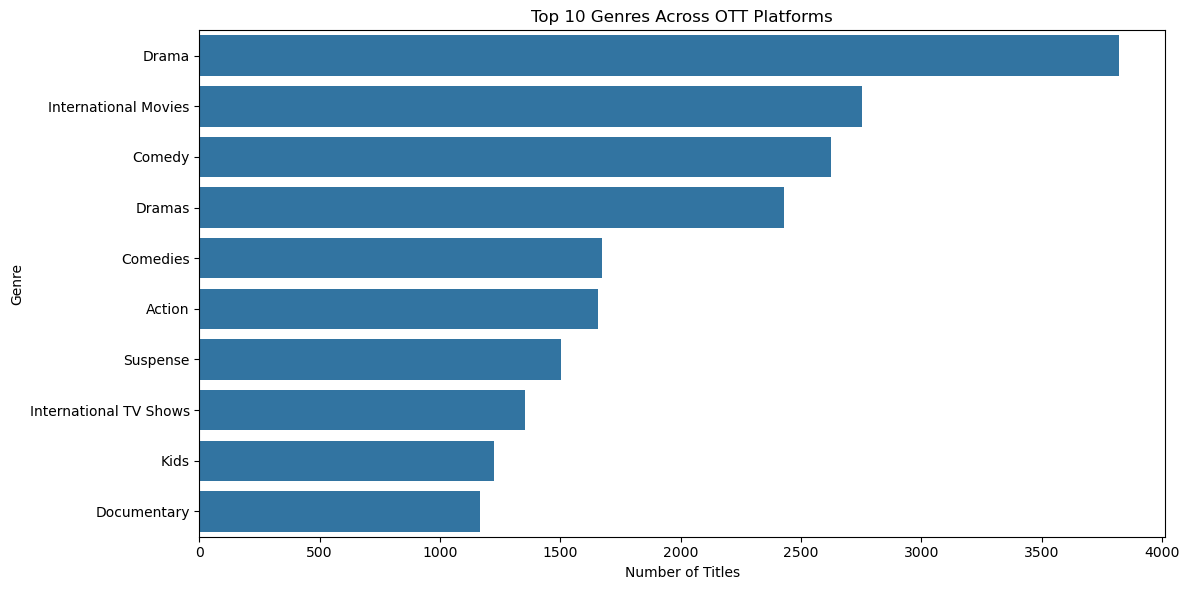

In [19]:
# Visualization 4: Top 10 Genres

genre_counts = (
    ott["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
    .head(10)
    .reset_index()
)

genre_counts.columns = ["genre", "title_count"]

plt.figure(figsize=(12, 6))

sns.barplot(
    data=genre_counts,
    x="title_count",
    y="genre"
)

plt.title("Top 10 Genres Across OTT Platforms")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

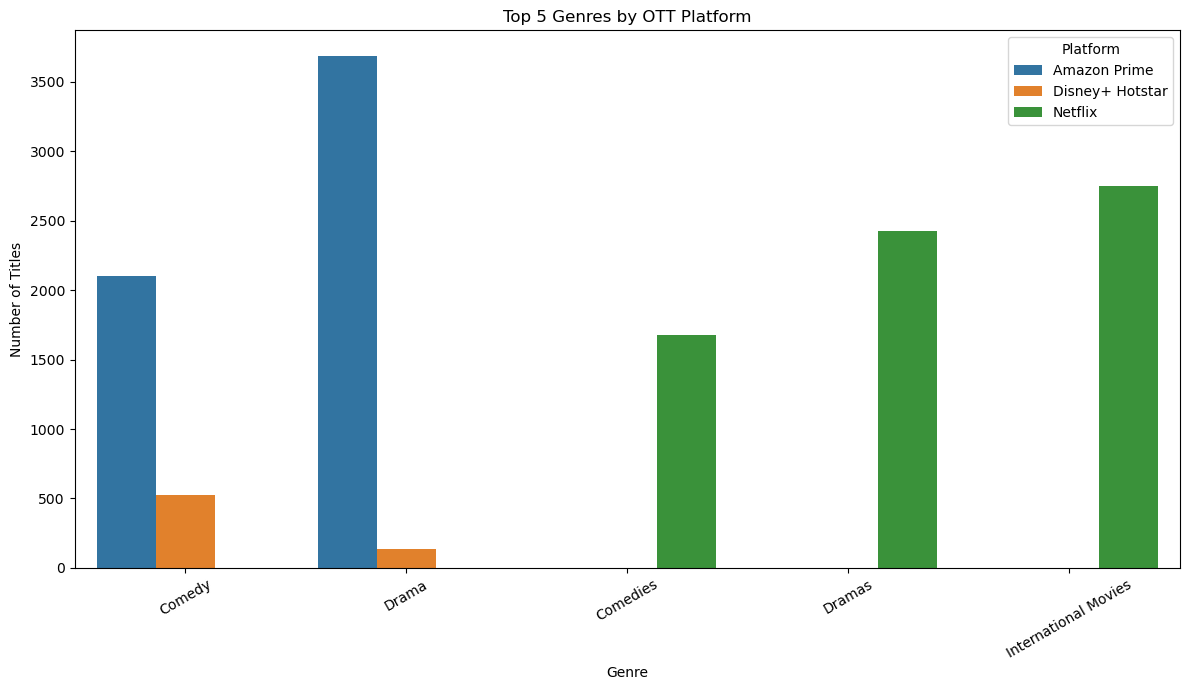

In [20]:
# Visualization 5: Top 5 Genres by Platform

genre_platform = (
    ott[["platform", "listed_in"]]
    .dropna()
    .assign(genre=lambda x: x["listed_in"].str.split(", "))
    .explode("genre")
)

top_5_genres = (
    genre_platform["genre"]
    .value_counts()
    .head(5)
    .index
)

genre_platform_top5 = genre_platform[
    genre_platform["genre"].isin(top_5_genres)
]

genre_platform_counts = (
    genre_platform_top5
    .groupby(["platform", "genre"])
    .size()
    .reset_index(name="title_count")
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=genre_platform_counts,
    x="genre",
    y="title_count",
    hue="platform"
)

plt.title("Top 5 Genres by OTT Platform")
plt.xlabel("Genre")
plt.ylabel("Number of Titles")
plt.xticks(rotation=30)
plt.legend(title="Platform")
plt.tight_layout()
plt.show()

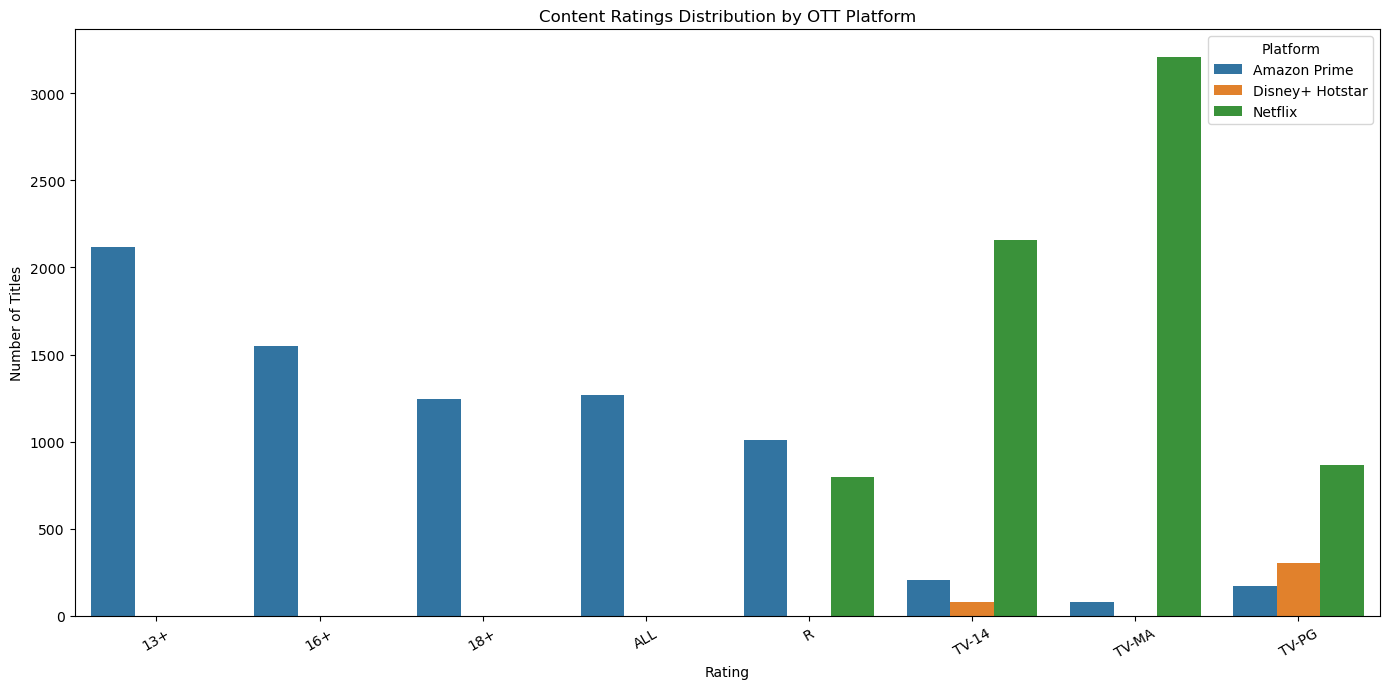

In [21]:
# Visualization 6: Content Ratings Distribution by Platform

rating_platform = (
    ott.groupby(["platform", "rating"])
       .size()
       .reset_index(name="title_count")
)

# Keep the most common ratings overall
top_ratings = (
    ott["rating"]
    .value_counts()
    .head(8)
    .index
)

rating_platform_top = rating_platform[
    rating_platform["rating"].isin(top_ratings)
]

plt.figure(figsize=(14, 7))

sns.barplot(
    data=rating_platform_top,
    x="rating",
    y="title_count",
    hue="platform"
)

plt.title("Content Ratings Distribution by OTT Platform")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=30)
plt.legend(title="Platform")
plt.tight_layout()
plt.show()

In [22]:
print("CONTENT STRATEGY MEMO")
print("=" * 50)

print("\nInsight 1: OTT content has expanded strongly over time.")
print("The combined catalog increased from 530 titles in 2012 "
      "to 2,159 titles in 2021.")
print("Action: Platforms should continue investing in high-demand "
      "content while monitoring changing audience preferences.")

print("\nInsight 2: Platform content mix differs significantly.")
print("Amazon Prime is more movie-focused, while Netflix has the "
      "highest proportion of TV Shows.")
print("Action: Platforms can strengthen their weaker content format "
      "to create a more balanced catalog.")

print("\nInsight 3: Drama and international content are major categories.")
print("Drama is the most common genre, while international content "
      "is also highly represented.")
print("Action: Content teams should prioritize successful genres "
      "while expanding localized and international content.")

CONTENT STRATEGY MEMO

Insight 1: OTT content has expanded strongly over time.
The combined catalog increased from 530 titles in 2012 to 2,159 titles in 2021.
Action: Platforms should continue investing in high-demand content while monitoring changing audience preferences.

Insight 2: Platform content mix differs significantly.
Amazon Prime is more movie-focused, while Netflix has the highest proportion of TV Shows.
Action: Platforms can strengthen their weaker content format to create a more balanced catalog.

Insight 3: Drama and international content are major categories.
Drama is the most common genre, while international content is also highly represented.
Action: Content teams should prioritize successful genres while expanding localized and international content.


In [23]:
import sqlite3

# Create an SQLite database
conn = sqlite3.connect("ott_analysis.db")

# Store the combined OTT dataset as a SQL table
ott.to_sql("ott_titles", conn, if_exists="replace", index=False)

print("SQL database created successfully!")
print("Table name: ott_titles")

SQL database created successfully!
Table name: ott_titles


In [24]:
query1 = """
SELECT platform, COUNT(*) AS title_count
FROM ott_titles
GROUP BY platform
ORDER BY title_count DESC;
"""

result1 = pd.read_sql_query(query1, conn)

print(result1)

          platform  title_count
0     Amazon Prime         9668
1          Netflix         8807
2  Disney+ Hotstar         1450


In [25]:
query2 = """
SELECT
    platform,
    type,
    COUNT(*) AS title_count
FROM ott_titles
GROUP BY platform, type
ORDER BY platform, title_count DESC;
"""

result2 = pd.read_sql_query(query2, conn)

print(result2)

          platform     type  title_count
0     Amazon Prime    Movie         7814
1     Amazon Prime  TV Show         1854
2  Disney+ Hotstar    Movie         1052
3  Disney+ Hotstar  TV Show          398
4          Netflix    Movie         6131
5          Netflix  TV Show         2676


In [26]:
query3 = """
SELECT
    release_year,
    COUNT(*) AS title_count
FROM ott_titles
WHERE release_year >= 2012
GROUP BY release_year
ORDER BY release_year;
"""

result3 = pd.read_sql_query(query3, conn)

print(result3)


   release_year  title_count
0          2012          530
1          2013          609
2          2014          793
3          2015          984
4          2016         1484
5          2017         1663
6          2018         1835
7          2019         2058
8          2020         2029
9          2021         2159


In [27]:
query4 = """
SELECT
    listed_in AS genre,
    COUNT(*) AS title_count
FROM ott_titles
WHERE listed_in IS NOT NULL
GROUP BY listed_in
ORDER BY title_count DESC
LIMIT 10;
"""

result4 = pd.read_sql_query(query4, conn)

print(result4)

                          genre  title_count
0                         Drama          989
1                        Comedy          544
2               Drama, Suspense          399
3                 Comedy, Drama          378
4                   Documentary          375
5               Animation, Kids          373
6  Dramas, International Movies          362
7                 Documentaries          359
8                          Kids          335
9               Stand-Up Comedy          334


In [28]:
query5 = """
SELECT
    platform,
    type,
    COUNT(*) AS title_count,
    ROUND(AVG(release_year), 1) AS avg_release_year
FROM ott_titles
GROUP BY platform, type
ORDER BY platform, type;
"""

result5 = pd.read_sql_query(query5, conn)

print(result5)

          platform     type  title_count  avg_release_year
0     Amazon Prime    Movie         7814            2006.9
1     Amazon Prime  TV Show         1854            2014.5
2  Disney+ Hotstar    Movie         1052            1999.2
3  Disney+ Hotstar  TV Show          398            2013.3
4          Netflix    Movie         6131            2013.1
5          Netflix  TV Show         2676            2016.6


In [29]:
# Export key analysis results to Excel

with pd.ExcelWriter("OTT_Content_Trend_Analysis.xlsx", engine="openpyxl") as writer:
    platform_counts.to_excel(writer, sheet_name="Platform Summary", index=False)
    type_percentage.reset_index().to_excel(writer, sheet_name="Content Type %", index=False)
    yearly_content.to_excel(writer, sheet_name="Yearly Trend", index=False)
    genre_counts.to_excel(writer, sheet_name="Top Genres", index=False)
    genre_platform_counts.to_excel(writer, sheet_name="Genre by Platform", index=False)
    rating_platform_top.to_excel(writer, sheet_name="Ratings by Platform", index=False)
    result1.to_excel(writer, sheet_name="SQL Platform", index=False)
    result2.to_excel(writer, sheet_name="SQL Content Type", index=False)
    result3.to_excel(writer, sheet_name="SQL Yearly Trend", index=False)
    result4.to_excel(writer, sheet_name="SQL Genres", index=False)
    result5.to_excel(writer, sheet_name="SQL Platform Type", index=False)

print("Excel file created successfully!")
print("File: OTT_Content_Trend_Analysis.xlsx")

Excel file created successfully!
File: OTT_Content_Trend_Analysis.xlsx
